## MTL Trajet: 22 Recurring Route Speed Destination Patterns (Flag 22)

### Dataset Overview

Multi-user recurring and occasional Montréal trajectories with route families, destinations, land-use, purpose, departure period, mode, GPS positions, and point speeds.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze characteristic patterns and variations in recurring urban mobility.

Role: Urban mobility-pattern analyst


Category: Multi-user recurring and occasional Montréal trajectories with route families, destinations, land-use, purpose, departure period, mode, GPS positions, and point speeds.

Distances and directness are calculated from delivered GPS polylines; point speeds, trip durations, chain timing, and paired-leg timing are synchronized with the supplied point table. Route directness ratio is route distance divided by straight-line distance, so it is at least 1 and lower values indicate more direct routes.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How similar are point-level speed profiles across uses of the same recurring route?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

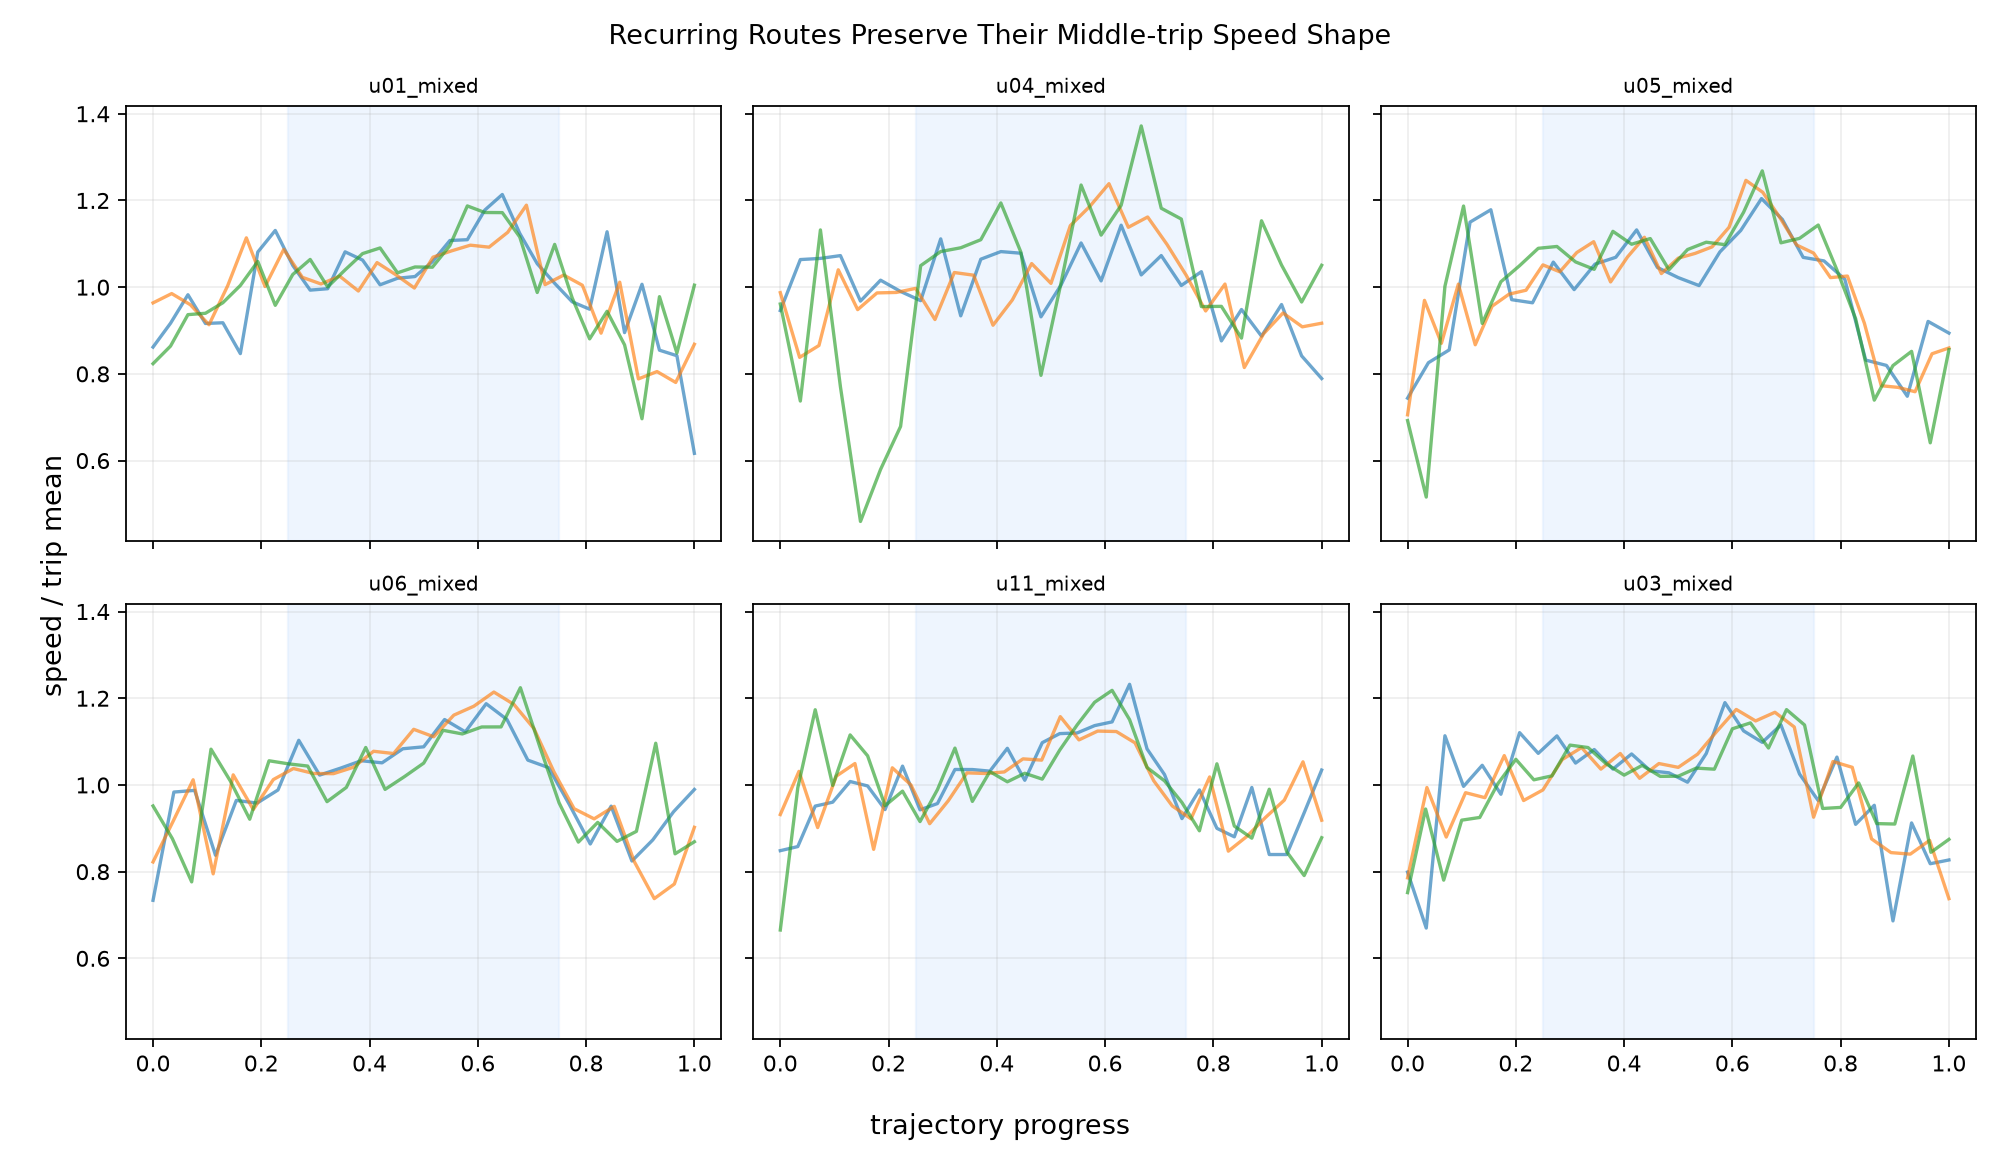

In [ ]:
df[df.recurrence_type.eq("recurring")].groupby("route_family")[
    ["middle_profile_similarity", "edge_profile_similarity"]
].first()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/recurring_speed_profiles.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurring_speed_profile",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Recurring-route Speed Profiles",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/recurring_speed_profiles.png"
  },
  "question": "How similar are point-level speed profiles across uses of the same recurring route?",
  "code": "df[df.recurrence_type.eq('recurring')].groupby('route_family')[['middle_profile_similarity','edge_profile_similarity']].first()",
  "insight": "Recurring routes generally preserve similar speed profiles, especially during the middle portions of trips.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id",
    "point_speed"
  ]
}

### **Question 2**: How do motor-vehicle speed fluctuation and lower-tail speed vary with rush-period proximity overall, and does the pattern persist within recurring route families?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

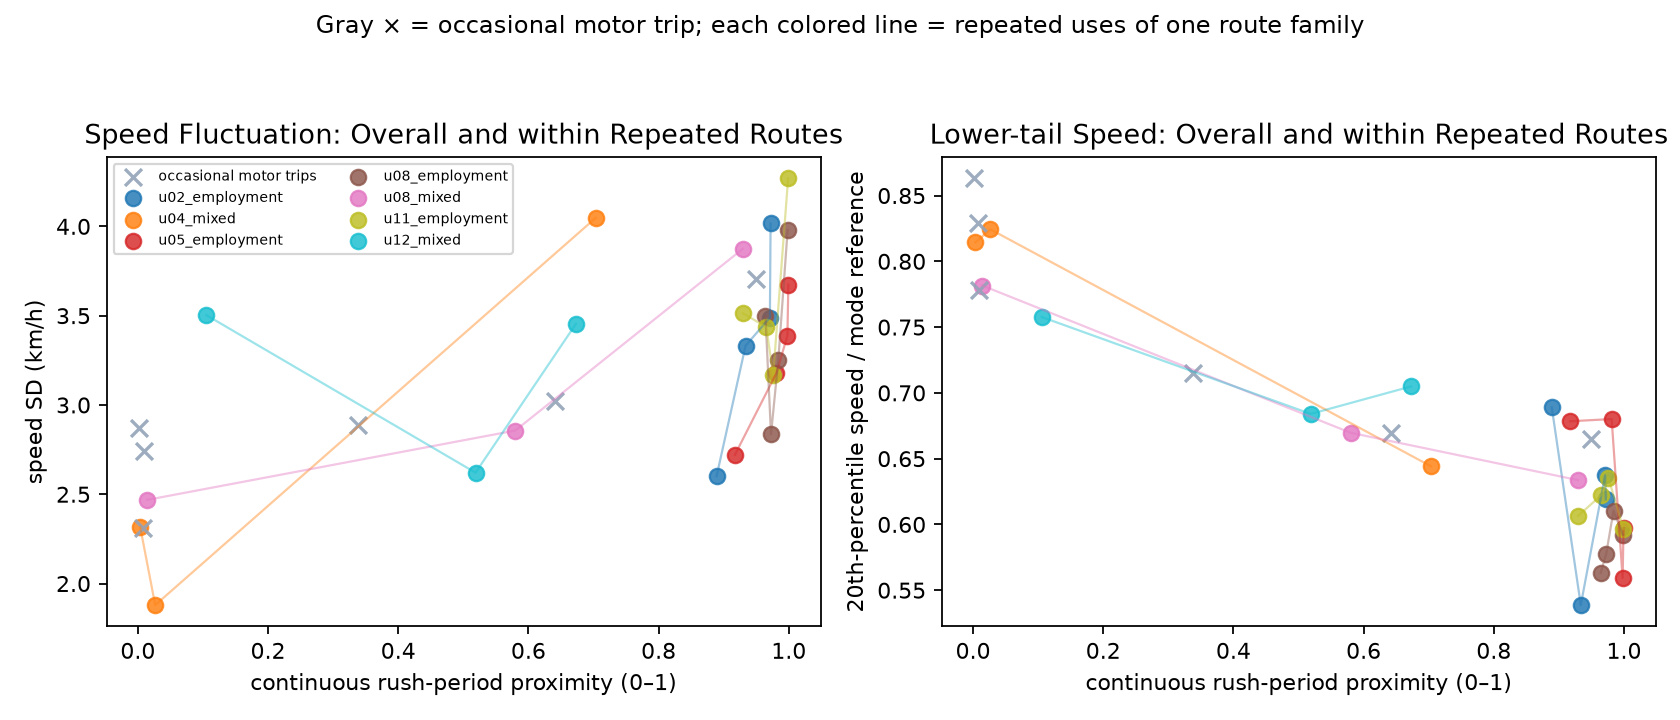

In [ ]:
motor = df[df.mode_group.eq("motor_vehicle")]
motor[
    [
        "start_hour",
        "rush_proximity_score",
        "speed_fluctuation_kmh",
        "lower_tail_speed_ratio",
    ]
].corr(method="spearman")
motor[motor.recurrence_type.eq("recurring")][
    ["rush_proximity_score", "speed_fluctuation_kmh", "lower_tail_speed_ratio"]
].corr(method="spearman")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/peak_motor_speed_disruption.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "peak_motor_speed_variation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Peak-period Motor-vehicle Speed Disruption",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/peak_motor_speed_disruption.png"
  },
  "question": "How do motor-vehicle speed fluctuation and lower-tail speed vary with rush-period proximity overall, and does the pattern persist within recurring route families?",
  "code": "motor=df[df.mode_group.eq('motor_vehicle')]; motor[['start_hour','rush_proximity_score','speed_fluctuation_kmh','lower_tail_speed_ratio']].corr(method='spearman'); motor[motor.recurrence_type.eq('recurring')][['rush_proximity_score','speed_fluctuation_kmh','lower_tail_speed_ratio']].corr(method='spearman')",
  "insight": "Motor-vehicle trips departing closer to peak periods show larger speed fluctuations and lower lower-tail speeds, even along repeatedly used routes.",
  "insight_type": "group_comparison",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id",
    "transport_mode",
    "trajectory_timestamp",
    "point_speed"
  ]
}

### **Question 3**: How do recurring employment and mixed-use trips differ in weekday concentration, mode consistency, purpose, and departure time?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

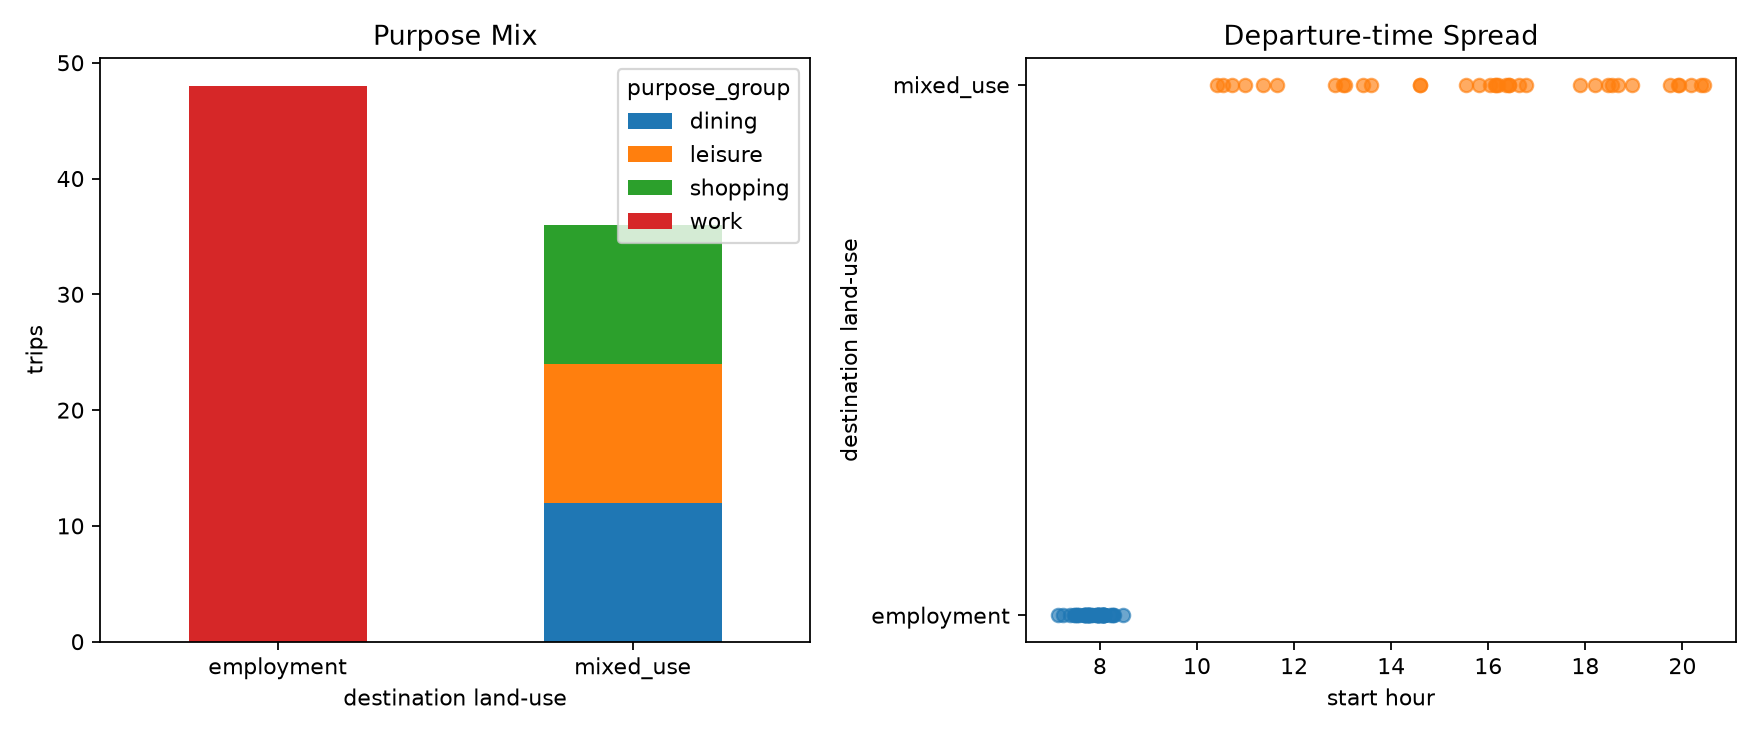

In [ ]:
df[df.recurrence_type.eq("recurring")].groupby("destination_land_use").agg(
    weekday_share=("is_weekday", "mean"),
    purposes=("purpose_group", "nunique"),
    start_std=("start_hour", "std"),
    modes=("mode_group", "nunique"),
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/employment_mixed_recurrence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "land_use_recurrence_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Employment and Mixed-use Recurrence",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/employment_mixed_recurrence.png"
  },
  "question": "How do recurring employment and mixed-use trips differ in weekday concentration, mode consistency, purpose, and departure time?",
  "code": "df[df.recurrence_type.eq('recurring')].groupby('destination_land_use').agg(weekday_share=('is_weekday','mean'),purposes=('purpose_group','nunique'),start_std=('start_hour','std'),modes=('mode_group','nunique'))",
  "insight": "Recurring trips to employment areas are more concentrated on weekdays and use consistent transportation modes, while repeated trips to mixed-use areas span more purposes and departure times.",
  "insight_type": "group_comparison",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id",
    "destination_land_use",
    "trajectory_timestamp",
    "transport_mode",
    "trip_purpose"
  ]
}

### **Question 4**: At equal trip sample sizes, how do recurring and occasional trips differ in destination and purpose diversity?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

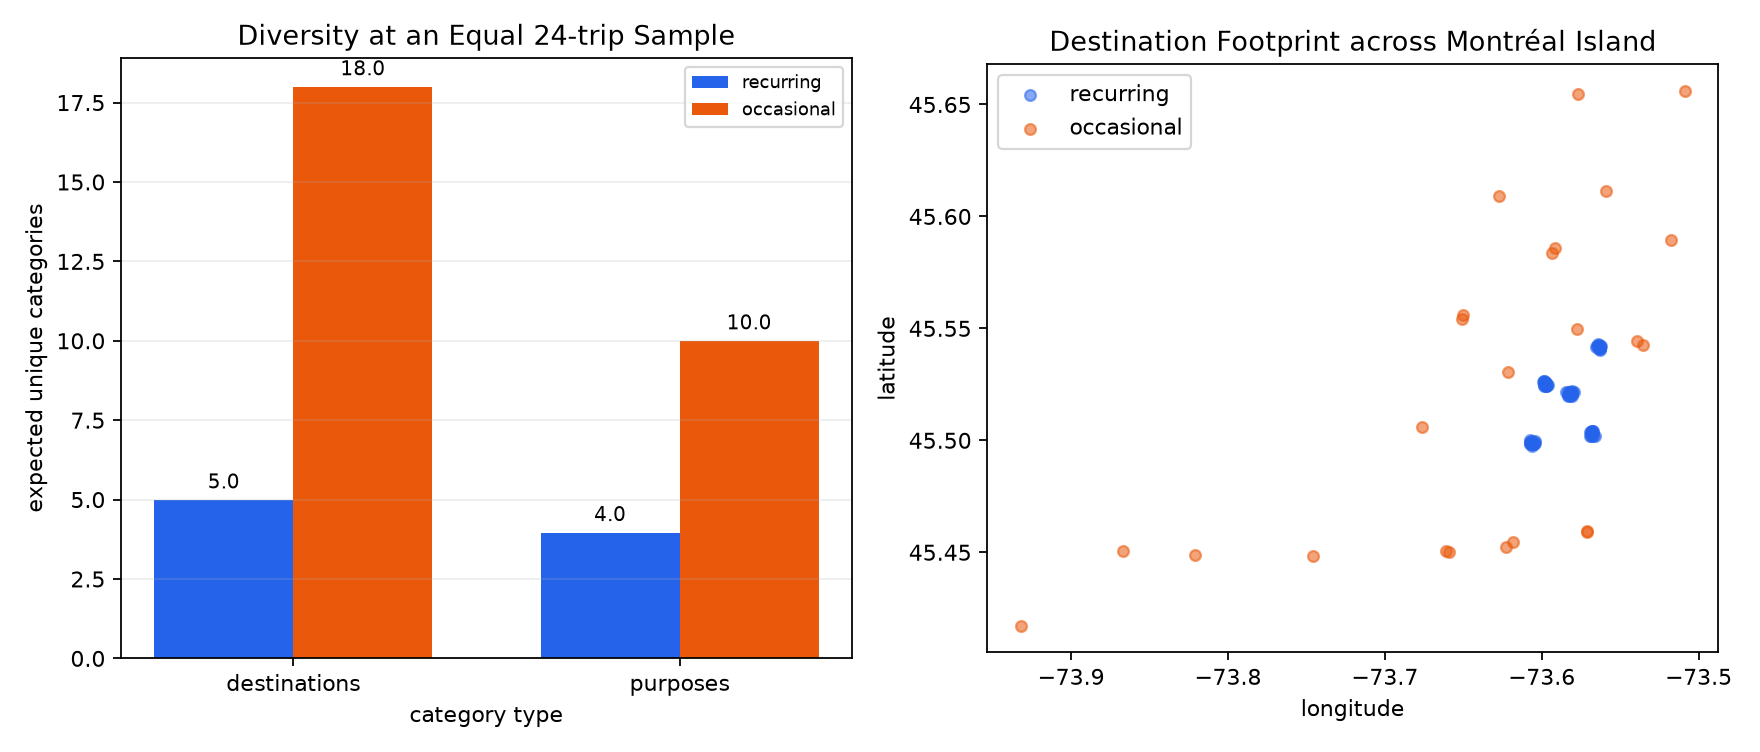

In [ ]:
from math import comb


def expected_unique(counts, k):
    n = int(counts.sum())
    return sum(
        1 - (comb(n - int(c), k) / comb(n, k) if k <= n - int(c) else 0) for c in counts
    )


sample_n = int(df.groupby("recurrence_type").size().min())
pd.DataFrame(
    {
        (kind, field): [expected_unique(group[field].value_counts(), sample_n)]
        for kind, group in df.groupby("recurrence_type")
        for field in ["destination_zone", "purpose_group"]
    }
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/recurring_occasional_diversity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "recurring_occasional_diversity",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Recurring Concentration and Occasional Diversity",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/recurring_occasional_diversity.png"
  },
  "question": "At equal trip sample sizes, how do recurring and occasional trips differ in destination and purpose diversity?",
  "code": "from math import comb\ndef expected_unique(counts, k):\n    n = int(counts.sum())\n    return sum(1 - (comb(n-int(c), k) / comb(n, k) if k <= n-int(c) else 0) for c in counts)\nsample_n = int(df.groupby('recurrence_type').size().min())\npd.DataFrame({(kind, field): [expected_unique(group[field].value_counts(), sample_n)] for kind, group in df.groupby('recurrence_type') for field in ['destination_zone','purpose_group']})",
  "insight": "Across users, recurring trips concentrate on a small set of destinations, while occasional trips account for most spatial and purpose diversity.",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id",
    "trip_purpose"
  ]
}

### Summary of Findings (Flag 22)

Repeated routes retain recognizable middle-trip speed shapes. Peak motor-vehicle repeats contain more disruption, employment recurrence is weekday- and mode-consistent, and occasional trips provide most of the destination and purpose diversity.